# 01. NFHS-5 Data Inspection & Variable Exploration
**Project:** `nfhs-diabetes-ml`  
**Objective:** Comprehensive inspection of the NFHS-5 Women's Individual Recode dataset using `pyreadstat`.  
**Tasks:**
1. File location, dimensions, schema, and metadata verification.
2. Value labels, unique values, min/max, and special sentinel code inspection.
3. Domain keyword search across 21 clinical, socioeconomic, and survey design categories.
4. Rigorous assessment of candidate diabetes variables (`s728a` vs. `s728b`) and data leakage risks.


In [1]:
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyreadstat

# Set working directory to project root if running from notebooks/
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

from src.config import PROJECT_ROOT, RAW_DATA_DIR, RANDOM_STATE
from src.utils import set_seed, setup_logger
from src.data_loader import load_raw_data, find_dta_file, decode_categoricals
from src.data_dictionary import (
    build_data_inventory,
    build_variable_dictionary,
    build_missingness_report,
    search_domains,
    DEFAULT_SPECIAL_CODES
)

set_seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print(f"Project root: {PROJECT_ROOT}")
print(f"Reproducibility seed: {RANDOM_STATE}")


Project root: C:\Users\Lenovo\OneDrive\Desktop\ml model\nfhs-diabetes-ml
Reproducibility seed: 42


## 1. Locate and Load Stata Dataset via `pyreadstat`

In [2]:
# Automatically locate and load .dta file
dta_path = find_dta_file()
print(f"Located DTA file: {dta_path}")
print(f"File size: {dta_path.stat().st_size / (1024*1024):.2f} MB")

df_raw, meta = load_raw_data(file_path=dta_path)

print(f"\nDataset Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Memory Usage: {df_raw.memory_usage(deep=True).sum() / (1024*1024):.2f} MB")
print(f"Data types distribution:\n{df_raw.dtypes.value_counts()}")


[2026-10-22 11:29:49] [INFO] [src.data_loader]: Located NFHS-5 DTA file at: C:\Users\Lenovo\OneDrive\Desktop\ml model\nfhs-diabetes-ml\data\raw\NFHS5_sample_individual.dta


[2026-10-22 11:29:49] [INFO] [src.data_loader]: Loading Stata dataset using pyreadstat from: C:\Users\Lenovo\OneDrive\Desktop\ml model\nfhs-diabetes-ml\data\raw\NFHS5_sample_individual.dta


[2026-10-22 11:29:50] [INFO] [src.data_loader]: Loaded dataset successfully: 12000 rows, 38 columns


Located DTA file: C:\Users\Lenovo\OneDrive\Desktop\ml model\nfhs-diabetes-ml\data\raw\NFHS5_sample_individual.dta
File size: 1.81 MB

Dataset Dimensions: 12,000 rows x 38 columns
Memory Usage: 4.05 MB
Data types distribution:
int64     37
object     1
Name: count, dtype: int64


## 2. Stata Variable Labels & Value Labels Inspection

In [3]:
# Display sample of variable labels from pyreadstat metadata
inventory_df = build_data_inventory(df_raw, meta)
inventory_df.head(15)


,variable,label,dtype,non_null_count,unique_values,min_val,max_val,special_codes_detected
0,caseid,Case Identification,object,12000,11993,100202102,999810501,None
1,v001,Cluster number (PSU),int64,12000,6615,1002.0,9998.0,None
2,v002,Household number,int64,12000,149,1.0,149.0,None
3,v003,Respondent's line number,int64,12000,9,1.0,9.0,None
4,v005,Sample weight (6 decimals),int64,12000,11938,187409.0,5581977.0,None
5,v012,Respondent's current age,int64,12000,35,15.0,49.0,None
6,v024,State / Union Territory,int64,12000,36,1.0,36.0,None
7,v025,Type of place of residence,int64,12000,2,1.0,2.0,None
8,v106,Highest educational level,int64,12000,4,0.0,3.0,None
9,v130,Religion,int64,12000,7,1.0,96.0,None


In [4]:
# Value label dictionaries extracted from Stata format
print(f"Total value-labeled variables: {len(meta.value_labels)}")
sample_labels = {k: meta.value_labels[k] for k in list(meta.value_labels.keys())[:5]}
for var, vdict in sample_labels.items():
    print(f"\nVariable [{var}]:\n  {vdict}")


Total value-labeled variables: 26

Variable [v025]:
  {1: 'Urban', 2: 'Rural'}

Variable [v106]:
  {0: 'No education', 1: 'Primary', 2: 'Secondary', 3: 'Higher'}

Variable [v190]:
  {1: 'Poorest', 2: 'Poorer', 3: 'Middle', 4: 'Richer', 5: 'Richest'}

Variable [v130]:
  {1: 'Hindu', 2: 'Muslim', 3: 'Christian', 4: 'Sikh', 5: 'Buddhist', 6: 'Jain', 96: 'Other'}

Variable [v131]:
  {1: 'Scheduled Caste', 2: 'Scheduled Tribe', 3: 'OBC', 4: 'General/None', 8: "Don't know"}


## 3. Missingness & Special NFHS Codes Analysis
In demographic health surveys (DHS/NFHS), missing values often take the form of numeric sentinel codes rather than standard system NaNs:
- `9998`: Anthropometry flagged / out of range / not measured / refused
- `998`: Blood pressure not measured / refused
- `8`: Don't know
- `9`: Missing / not applicable


In [5]:
missingness_df = build_missingness_report(df_raw, meta)
# Show variables with effective missingness
vars_with_missing = missingness_df[missingness_df["effective_missing_count"] > 0]
print(f"Variables with special/sentinel codes: {len(vars_with_missing)}")
vars_with_missing.sort_values(by="effective_missing_pct", ascending=False)


Variables with special/sentinel codes: 22


,variable,variable_label,total_rows,raw_nan_count,sentinel_missing_count,effective_missing_count,effective_missing_pct,special_codes_breakdown
18,sb221,Systolic blood pressure (mmHg),12000,0,483,483,4.03,code_998=483
19,sb222,Diastolic blood pressure (mmHg),12000,0,483,483,4.03,code_998=483
15,v438,Height in cm (1 decimal),12000,0,373,373,3.11,code_9998=373
16,v445,Body Mass Index (2 decimals),12000,0,373,373,3.11,code_9998=373
17,v447,Weight in kg (1 decimal),12000,0,373,373,3.11,code_9998=373
10,v131,Caste or tribe,12000,0,214,214,1.78,code_8=214
31,s706i,Diet frequency: Aerated drinks,12000,0,136,136,1.13,code_9=136
13,v714,Respondent currently working,12000,0,136,136,1.13,code_9=136
27,s706e,Diet frequency: Eggs,12000,0,130,130,1.08,code_9=130
20,s728c,Told by doctor: High blood pressure / hyperten...,12000,0,127,127,1.06,code_9=127


## 4. Domain Keyword Search across 21 Categories
Searching variable names and Stata labels for:
Diabetes, Blood pressure, Hypertension, BMI, Height, Weight, Waist circumference, Hip circumference, Age, Residence, State/region, Education, Occupation, Wealth index, Health insurance, Tobacco, Alcohol, Diet, Healthcare access, Survey weights, PSU, and Strata.


In [6]:
domain_results = search_domains(df_raw, meta)

domain_summary = []
for domain, items in domain_results.items():
    var_list = [it["variable"] for it in items]
    domain_summary.append({
        "Domain": domain,
        "Matches Count": len(items),
        "Matched Variables": ", ".join(var_list) if var_list else "(None in file)"
    })

domain_summary_df = pd.DataFrame(domain_summary)
domain_summary_df


,Domain,Matches Count,Matched Variables
0,Diabetes,2,"s728a, s728b"
1,Blood pressure,3,"sb221, sb222, s728c"
2,Hypertension,1,s728c
3,BMI,1,v445
4,Height,1,v438
5,Weight,2,"v005, v447"
6,Waist circumference,0,(None in file)
7,Hip circumference,0,(None in file)
8,Age,1,v012
9,Residence,1,v025


## 5. Candidate Diabetes Variables & Leakage Assessment
We inspect both candidate diabetes variables:
1. `s728a`: Told by doctor: Diabetes
2. `s728b`: Currently taking medicine for diabetes (CRITICAL LEAKAGE)


In [7]:
print("=== s728a (Diagnosed Diabetes) ===")
print(df_raw["s728a"].value_counts().rename(index=meta.value_labels.get("s728a", {})))

print("\n=== s728b (Taking Medication) ===")
print(df_raw["s728b"].value_counts().rename(index=meta.value_labels.get("s728b", {})))

print("\n=== Cross-Tabulation (s728a vs s728b) ===")
crosstab = pd.crosstab(
    df_raw["s728a"].map(meta.value_labels.get("s728a", {})),
    df_raw["s728b"].map(meta.value_labels.get("s728b", {})),
    margins=True
)
crosstab


=== s728a (Diagnosed Diabetes) ===
s728a
No            11631
Yes             267
Don't know       54
Missing          48
Name: count, dtype: int64

=== s728b (Taking Medication) ===
s728b
No         11684
Yes          214
Missing      102
Name: count, dtype: int64

=== Cross-Tabulation (s728a vs s728b) ===


s728b,Missing,No,Yes,All
s728a,,,,
Don't know,54,0,0,54
Missing,48,0,0,48
No,0,11622,9,11631
Yes,0,62,205,267
All,102,11684,214,12000


In [8]:
# Calculate target prevalence among valid respondents (excluding 8=Don't know and 9=Missing)
valid_mask = df_raw["s728a"].isin([0, 1])
n_valid = valid_mask.sum()
n_positive = (df_raw.loc[valid_mask, "s728a"] == 1).sum()
prevalence = (n_positive / n_valid) * 100

print(f"Valid Cohort: {n_valid:,} respondents")
print(f"Diabetes Positive Cases: {n_positive} ({prevalence:.2f}%)")
print(f"Class Imbalance Ratio: {(n_valid - n_positive) / n_positive:.1f} : 1")


Valid Cohort: 11,898 respondents
Diabetes Positive Cases: 267 (2.24%)
Class Imbalance Ratio: 43.6 : 1


## 6. Exploratory Visualizations

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_31820\1966583845.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_31820\1966583845.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["Non-Diabetic (0)", "Diabetic (1)"])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_31820\1966583845.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_prev.index, y=age_prev.values, ax=axes[1], palette="Blues_d")


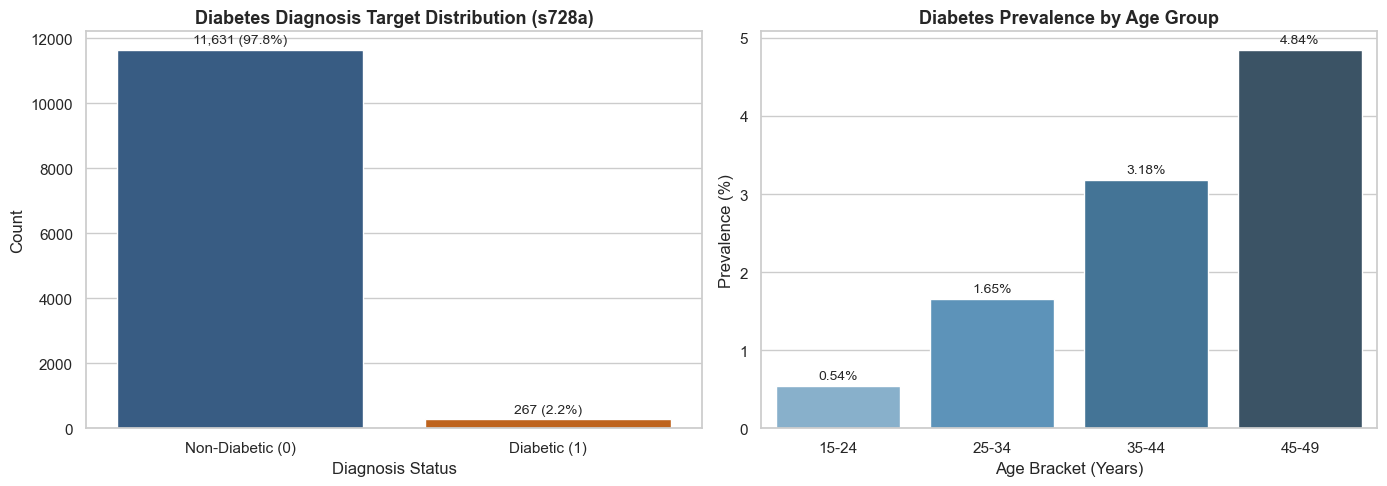

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Target distribution
sns.countplot(
    data=df_raw[valid_mask],
    x="s728a",
    ax=axes[0],
    palette=["#2b5c8f", "#d95f02"]
)
axes[0].set_title("Diabetes Diagnosis Target Distribution (s728a)", fontsize=13, fontweight="bold")
axes[0].set_xticklabels(["Non-Diabetic (0)", "Diabetic (1)"])
axes[0].set_xlabel("Diagnosis Status")
axes[0].set_ylabel("Count")

# Add count labels
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,} ({p.get_height()/n_valid*100:.1f}%)",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="baseline", fontsize=10,
                    xytext=(0, 5), textcoords="offset points")

# Plot 2: Prevalence by Age Groups
df_eda = df_raw[valid_mask].copy()
df_eda["age_group"] = pd.cut(df_eda["v012"], bins=[14, 24, 34, 44, 50], labels=["15-24", "25-34", "35-44", "45-49"])
age_prev = df_eda.groupby("age_group", observed=False)["s728a"].mean() * 100

sns.barplot(x=age_prev.index, y=age_prev.values, ax=axes[1], palette="Blues_d")
axes[1].set_title("Diabetes Prevalence by Age Group", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Age Bracket (Years)")
axes[1].set_ylabel("Prevalence (%)")

for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2f}%",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="baseline", fontsize=10,
                    xytext=(0, 5), textcoords="offset points")

plt.tight_layout()
os.makedirs("reports/figures", exist_ok=True)
plt.savefig("reports/figures/eda_target_and_age.png", dpi=200)
plt.show()


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_31820\848569756.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[wealth_labels.get(i, str(i)) for i in wealth_prev.index], y=wealth_prev.values, ax=axes[0], palette="Greens_d")
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_31820\848569756.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=bp_clean, x="s728a", y="sb221", ax=axes[1], palette=["#2b5c8f", "#d95f02"])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_31820\848569756.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["Non-Diabetic", "Diabetic"])


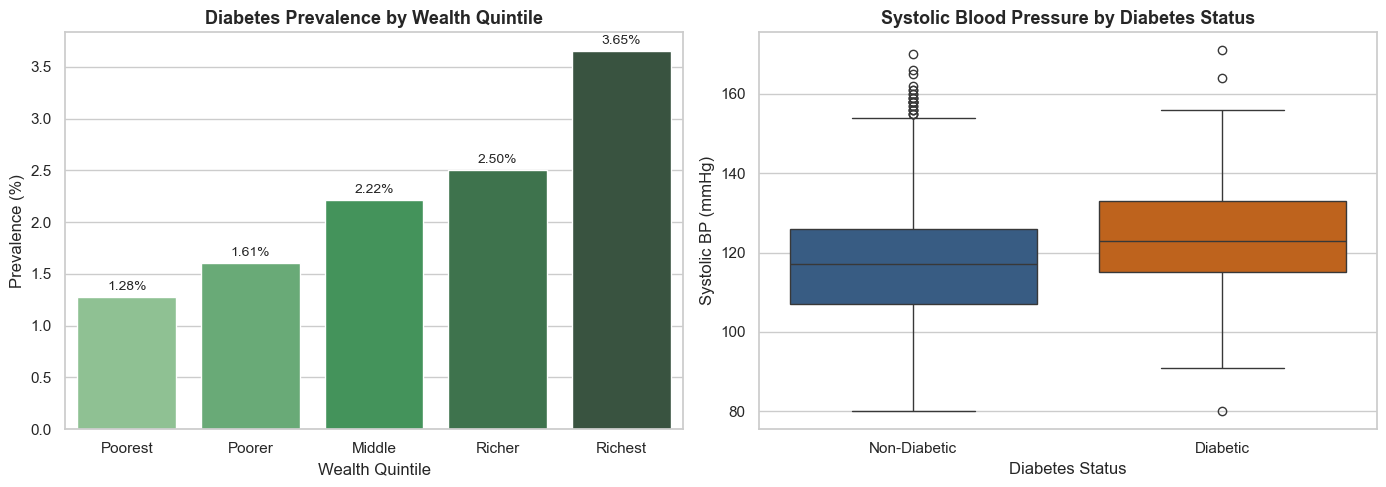

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 3: Diabetes Prevalence by Wealth Quintile
wealth_labels = {1: "Poorest", 2: "Poorer", 3: "Middle", 4: "Richer", 5: "Richest"}
wealth_prev = df_eda.groupby("v190")["s728a"].mean() * 100

sns.barplot(x=[wealth_labels.get(i, str(i)) for i in wealth_prev.index], y=wealth_prev.values, ax=axes[0], palette="Greens_d")
axes[0].set_title("Diabetes Prevalence by Wealth Quintile", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Wealth Quintile")
axes[0].set_ylabel("Prevalence (%)")

for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}%",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="baseline", fontsize=10,
                    xytext=(0, 5), textcoords="offset points")

# Plot 4: Blood Pressure Distribution (Cleaned of 998 sentinel codes)
bp_clean = df_eda[df_eda["sb221"] < 900].copy()
sns.boxplot(data=bp_clean, x="s728a", y="sb221", ax=axes[1], palette=["#2b5c8f", "#d95f02"])
axes[1].set_title("Systolic Blood Pressure by Diabetes Status", fontsize=13, fontweight="bold")
axes[1].set_xticklabels(["Non-Diabetic", "Diabetic"])
axes[1].set_xlabel("Diabetes Status")
axes[1].set_ylabel("Systolic BP (mmHg)")

plt.tight_layout()
plt.savefig("reports/figures/eda_wealth_and_bp.png", dpi=200)
plt.show()


## 7. Conclusions & Modeling Pipeline Directives

1. **Target Selection:** Use `s728a` (binary mapping: 0=No, 1=Yes; omit 8 and 9). The target has 267 positive cases (2.24% prevalence).
2. **Data Leakage Mitigation:** Exclude `s728b` ("Taking medication for diabetes") from input features.
3. **Data Cleaning:** Convert sentinel codes `9998` (anthropometry), `998` (blood pressure), and `9` (demographic/diet missing) to `np.nan` before scaling/imputation.
4. **Imbalance Strategy:** With a 43.5:1 imbalance, evaluate models with PR-AUC, Stratified 5-Fold CV, and class weights or SMOTE.
5. **No Model Training:** Data inspection completed. Ready for review.
